# HASTS206 — Assignment 2
## Applied Demographic & Actuarial Analysis of Zimbabwean Districts

**Author:** <your name> | **Student ID:** <id>

### Two clients, two problems

**Client 1 — Zimbabwean Planning Team**
> "How are district populations changing, what drives the change, and what will they look like in 2030?"

**Client 2 — Zimbabwean Insurer**
> "How do insured lives move between Healthy, Ill and Dead? What should we expect to pay in death benefits?"

### Four analytical workstreams (20 marks each)

| # | Workstream | Data |
|---|---|---|
| 1 | Population structure & mortality | age_sex, districts, life_table_inputs |
| 2 | Population projections | districts, age_sex, projection_scenarios |
| 3 | Continuous-time Markov model | insured_transitions |
| 4 | District clustering | age_sex, districts |

### Notebook structure (10 sections)

1. Introduction & objectives ← you are here
2. Data loading and quality audit
3. Population structure & district selection
4. Population balance & demographic rates
5. Abridged life table
6. Arithmetic & geometric projections
7. Cohort-component projection (Low/Base/High + fertility sensitivity)
8. Three-state continuous-time Markov model
9. District clustering (k-means)
10. Exports, interpretation, reproducibility

## 1. Introduction and analytical objectives

This notebook builds four **independent** models. They share data sources but are *not* one continuous model — the life table, the Markov model, and the projection each answer different questions.

**Reproducibility**: run top-to-bottom in a clean environment. All outputs written to `output/`.

**Key assumptions documented inline** — these become part of the six-page report.

## 2. Data loading and quality audit

We load all five CSVs, then produce a **formal data-quality log**:

* Row/column counts and dtypes
* Missing values by column
* Duplicate keys
* Age band coverage (should be 0,5,...,85 per sex per district)
* Valid ranges (sex ∈ {F,M}, non-negative counts)
* Join cardinalities (district_id, age_start, scenario, state codes)
* Population totals reconciliation (age_sex vs districts)

importing the neccessary libraries

In [2]:
pip install pandas numpy matplotlib seaborn scipy scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ============================================================
# SETUP
# ============================================================
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import expm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

OUT = Path("output"); OUT.mkdir(exist_ok=True)

AGE_BANDS = list(range(0, 90, 5))
AGE_LABELS = [f"{a}-{a+4}" if a < 85 else "85+" for a in AGE_BANDS]
def age_label(a): return f"{a}-{a+4}" if a < 85 else "85+"
def broad_group(a):
    return "0-14" if a < 15 else ("15-64" if a < 65 else "65+")

RADIX = 100_000.0
print("Setup complete.")

Setup complete.


In [4]:
# ============================================================
# 2.1 LOAD DATA
# ============================================================
age_sex   = pd.read_csv("age_sex.csv")
districts = pd.read_csv("districts.csv")
life      = pd.read_csv("life_table_inputs.csv")
scen      = pd.read_csv("projection_scenarios.csv")
trans     = pd.read_csv("insured_transitions.csv")

print("Shapes:")
for n, d in [("age_sex", age_sex), ("districts", districts),
             ("life", life), ("scen", scen), ("trans", trans)]:
    print(f"  {n:10s} {d.shape}")

Shapes:
  age_sex    (864, 9)
  districts  (24, 10)
  life       (18, 5)
  scen       (3, 6)
  trans      (96, 6)


In [5]:
# ============================================================
# 2.2 DATA-QUALITY LOG
# ============================================================
def audit(name, df, key_cols=None):
    log = {"table": name, "rows": len(df), "cols": df.shape[1],
           "missing_cells": int(df.isna().sum().sum())}
    if key_cols:
        log["duplicate_keys"] = int(df.duplicated(subset=key_cols).sum())
    else:
        log["duplicate_keys"] = 0
    return log

audit_rows = [
    audit("age_sex",   age_sex,   ["district_id","age_start","sex"]),
    audit("districts", districts, ["district_id"]),
    audit("life",      life,      ["age_start"]),
    audit("scen",      scen,      ["scenario"]),
    audit("trans",     trans,     ["district_id","origin","destination"]),
]
audit_df = pd.DataFrame(audit_rows)
print("=== DATA QUALITY LOG ===")
print(audit_df.to_string(index=False))

# Missingness detail
print("\n=== MISSING VALUES BY TABLE ===")
for n, d in [("age_sex", age_sex), ("districts", districts),
             ("life", life), ("scen", scen), ("trans", trans)]:
    miss = d.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f"\n{n}:")
        print(miss.to_string())

# Age-band coverage: every district-sex should have all 18 bands
coverage = (age_sex.groupby(["district_id","sex"])
            .size().rename("bands").reset_index())
print(f"\nAge-band coverage: min={coverage.bands.min()}, max={coverage.bands.max()} (expect 18)")

# Valid sex codes
assert set(age_sex.sex.unique()) == {"F","M"}, "Unexpected sex codes"

# Non-negative counts
count_cols = ["population_2025","baseline_deaths_2025","arrivals_2025",
              "departures_2025","births_to_women_2025"]
neg = (age_sex[count_cols] < 0).sum().sum()
print(f"Negative count cells in age_sex: {neg} (expect 0)")

# Births structural zeros for males
male_births = age_sex.loc[age_sex.sex == "M", "births_to_women_2025"].sum()
print(f"Births on male rows (should be 0): {male_births}")

audit_df.to_csv(OUT / "data_quality_log.csv", index=False)
print("\nSaved -> output/data_quality_log.csv")

=== DATA QUALITY LOG ===
    table  rows  cols  missing_cells  duplicate_keys
  age_sex   864     9              0               0
districts    24    10              2               0
     life    18     5              2               0
     scen     3     6              0               0
    trans    96     6              0               0

=== MISSING VALUES BY TABLE ===

districts:
piped_water_pct    2

life:
interval_years    1
ax                1

Age-band coverage: min=18, max=18 (expect 18)
Negative count cells in age_sex: 0 (expect 0)
Births on male rows (should be 0): 0

Saved -> output/data_quality_log.csv


## 3. Population structure and district selection

We first compute district-level indicators across all 24 districts, then select **two contrasting districts** for detailed pyramids and rate analysis.

Selection criteria:
* **% under 15** (youthful vs mature)
* **% aged 65+** (young vs ageing)
* **Net migration rate** (growth vs decline pressure)
* **Piped-water access** (socioeconomic contrast)

In [6]:
# ============================================================
# 3.1 DISTRICT INDICATORS (all 24)
# ============================================================
def district_indicators(df):
    young  = df.loc[df.age_start < 15,   "population_2025"].sum()
    work   = df.loc[(df.age_start>=15)&(df.age_start<65), "population_2025"].sum()
    old    = df.loc[df.age_start >= 65,  "population_2025"].sum()
    total  = young + work + old
    return pd.Series({
        "pop_total": total,
        "pct_under15": 100*young/total,
        "pct_65plus":  100*old  /total,
        "pct_working": 100*work /total,
        "youth_dep_ratio": 100*young/work,
        "old_dep_ratio":   100*old  /work,
        "total_dep_ratio": 100*(young+old)/work,
    })

ind = (age_sex.groupby("district_id").apply(district_indicators)
       .reset_index()
       .merge(districts[["district_id","district_name","region","piped_water_pct"]],
              on="district_id"))
print(ind.sort_values("pct_under15", ascending=False).to_string(index=False))

district_id    pop_total  pct_under15  pct_65plus  pct_working  youth_dep_ratio  old_dep_ratio  total_dep_ratio district_name   region  piped_water_pct
        D19  82,645.0000      29.9558     14.9338      55.1104          54.3560        27.0979          81.4539  District D19 Region 3          39.0000
        D07  44,047.0000      29.4594     14.5867      55.9539          52.6495        26.0691          78.7187  District D07 Region 3          44.5000
        D01 172,445.0000      29.2748     14.6337      56.0915          52.1912        26.0889          78.2801  District D01 Region 1          31.3000
        D10 111,451.0000      29.1321     14.5660      56.3019          51.7427        25.8713          77.6140  District D10 Region 4          33.5000
        D16  44,988.0000      28.8099     14.4928      56.6973          50.8135        25.5616          76.3751  District D16 Region 2          35.8000
        D13 174,620.0000      28.6937     14.5018      56.8045          50.5131        2

In [7]:
# ============================================================
# 3.2 SELECT TWO CONTRASTING DISTRICTS
# ============================================================
# Score each district on "youthful + high water" vs "ageing + low water"
ind["_score"] = (ind["pct_under15"].rank(pct=True)
                 + ind["piped_water_pct"].rank(pct=True, na_option="bottom")
                 - ind["pct_65plus"].rank(pct=True))

candidate_A = ind.sort_values("_score", ascending=False).iloc[0]
candidate_B = ind.sort_values("_score", ascending=True).iloc[0]

DA = candidate_A["district_id"]; DB = candidate_B["district_id"]
print(f"Selected contrasting districts:")
print(f"  District A: {DA} ({candidate_A.district_name}) - youthful, high water access")
print(f"  District B: {DB} ({candidate_B.district_name}) - ageing, low water access")
print()
print(ind.loc[ind.district_id.isin([DA,DB]),
              ["district_id","district_name","pct_under15","pct_65plus",
               "youth_dep_ratio","old_dep_ratio","piped_water_pct"]].to_string(index=False))

Selected contrasting districts:
  District A: D02 (District D02) - youthful, high water access
  District B: D18 (District D18) - ageing, low water access

district_id district_name  pct_under15  pct_65plus  youth_dep_ratio  old_dep_ratio  piped_water_pct
        D02  District D02      13.2928     12.4088          17.8911        16.7013          80.5000
        D18  District D18       9.4033     28.6293          15.1746        46.2006          51.0000


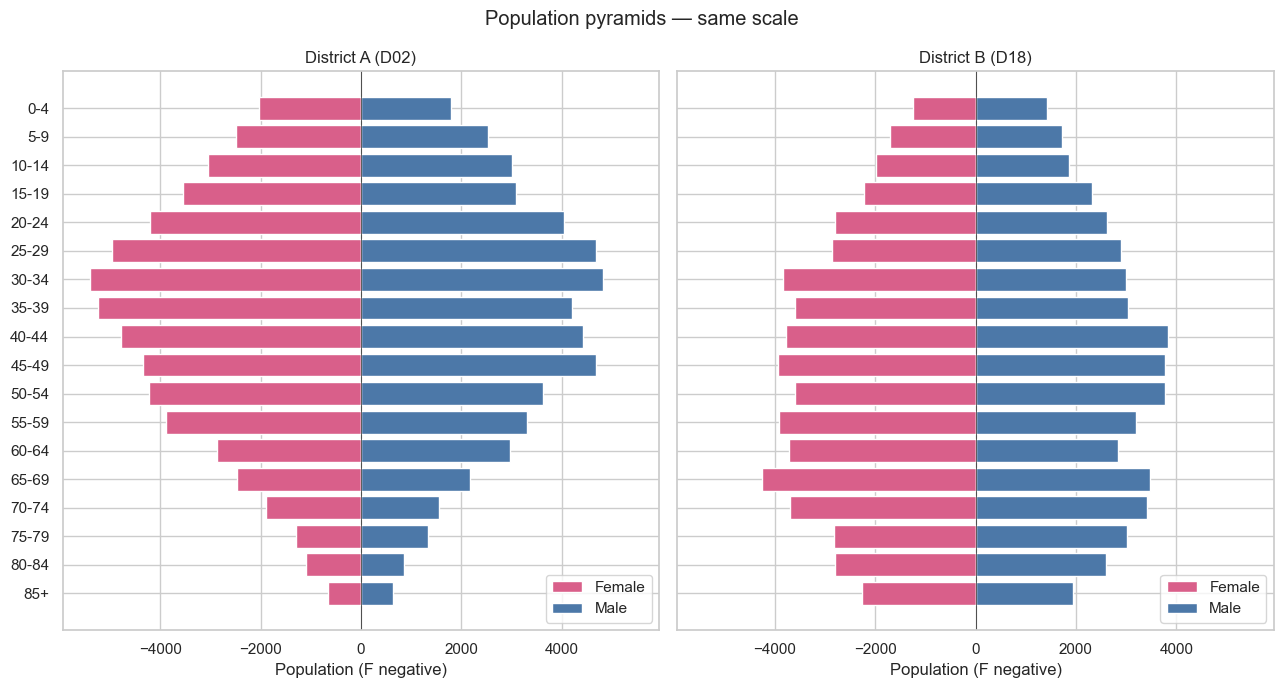


Sex ratios — District A (D02):
sex       F     M  sex_ratio
0-4    2030  1787    88.0296
5-9    2498  2540   101.6813
10-14  3049  3012    98.7865
15-19  3541  3095    87.4047
20-24  4214  4042    95.9184
25-29  4964  4686    94.3997
30-34  5407  4825    89.2362
35-39  5243  4209    80.2785
40-44  4774  4432    92.8362
45-49  4350  4695   107.9310
50-54  4221  3634    86.0933
55-59  3895  3312    85.0321
60-64  2862  2970   103.7736
65-69  2461  2165    87.9724
70-74  1884  1552    82.3779
75-79  1300  1332   102.4615
80-84  1097   851    77.5752
85+     652   630    96.6258

Sex ratios — District B (D18):
sex       F     M  sex_ratio
0-4    1255  1420   113.1474
5-9    1706  1726   101.1723
10-14  1986  1860    93.6556
15-19  2228  2311   103.7253
20-24  2801  2619    93.5023
25-29  2869  2893   100.8365
30-34  3844  2989    77.7575
35-39  3610  3044    84.3213
40-44  3783  3825   101.1102
45-49  3934  3780    96.0854
50-54  3595  3779   105.1182
55-59  3924  3188    81.2436
60-64  3

In [8]:
# ============================================================
# 3.3 POPULATION PYRAMIDS (same x-axis scale)
# ============================================================
def pyramid_df(df):
    p = df.groupby(["age_start","sex"])["population_2025"].sum().unstack("sex").fillna(0)
    p = p.reindex(AGE_BANDS, fill_value=0).sort_index(ascending=False)
    return p

pA, pB = pyramid_df(age_sex[age_sex.district_id==DA]), pyramid_df(age_sex[age_sex.district_id==DB])
xmax = max(pA.values.max(), pB.values.max()) * 1.1

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, p, title, did in [(axes[0], pA, "District A", DA), (axes[1], pB, "District B", DB)]:
    y = [age_label(a) for a in p.index]
    ax.barh(y, -p["F"], color="#d95f8a", label="Female")
    ax.barh(y,  p["M"], color="#4c78a8", label="Male")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlim(-xmax, xmax)
    ax.set_title(f"{title} ({did})")
    ax.set_xlabel("Population (F negative)")
    ax.legend(loc="lower right")
plt.suptitle("Population pyramids — same scale")
plt.tight_layout(); plt.show()

# Sex ratio per age band per district
def sex_ratio_table(df):
    sr = df.groupby(["age_start","sex"])["population_2025"].sum().unstack("sex")
    sr["sex_ratio"] = 100 * sr["M"] / sr["F"]
    sr.index = [age_label(a) for a in sr.index]
    return sr
print(f"\nSex ratios — District A ({DA}):"); print(sex_ratio_table(age_sex[age_sex.district_id==DA]).to_string())
print(f"\nSex ratios — District B ({DB}):"); print(sex_ratio_table(age_sex[age_sex.district_id==DB]).to_string())

In [10]:
# ============================================================
# 4. POPULATION BALANCE & RATES
# ============================================================
pop_2025_agesex = (age_sex.groupby("district_id")["population_2025"].sum()
                   .rename("pop_2025").reset_index())

balance = districts.merge(pop_2025_agesex, on="district_id")
balance["pop_2026_calc"] = (balance["pop_2025"] + balance["births_2025"]
                            + balance["arrivals_2025"] - balance["deaths_2025"]
                            - balance["departures_2025"])
balance["balance_gap"] = balance["pop_2026_calc"] - balance["population_2026"]
balance["mid_year_exposure"] = (balance["pop_2025"] + balance["pop_2026_calc"]) / 2

balance["CBR"] = 1000 * balance["births_2025"] / balance["mid_year_exposure"]
balance["CDR"] = 1000 * balance["deaths_2025"] / balance["mid_year_exposure"]
balance["NMR"] = 1000 * (balance["arrivals_2025"] - balance["departures_2025"]) / balance["mid_year_exposure"]

In [11]:
# ============================================================
# 4. POPULATION BALANCE & RATES
# ============================================================
pop_2025_agesex = (age_sex.groupby("district_id")["population_2025"].sum()
                   .rename("pop_2025").reset_index())

balance = districts.merge(pop_2025_agesex, on="district_id")
balance["pop_2026_calc"] = (balance["pop_2025"] + balance["births_2025"]
                            + balance["arrivals_2025"] - balance["deaths_2025"]
                            - balance["departures_2025"])
balance["balance_gap"] = balance["pop_2026_calc"] - balance["population_2026"]
balance["mid_year_exposure"] = (balance["pop_2025"] + balance["pop_2026_calc"]) / 2

balance["CBR"] = 1000 * balance["births_2025"] / balance["mid_year_exposure"]
balance["CDR"] = 1000 * balance["deaths_2025"] / balance["mid_year_exposure"]
balance["NMR"] = 1000 * (balance["arrivals_2025"] - balance["departures_2025"]) / balance["mid_year_exposure"]

print("=== BALANCE CHECK (first 10) ===")
print(balance[["district_id","pop_2025","births_2025","arrivals_2025",
               "deaths_2025","departures_2025","pop_2026_calc",
               "population_2026","balance_gap"]].head(10).to_string(index=False))

print(f"\nDistricts with |balance_gap| >= 1: {(balance.balance_gap.abs()>=1).sum()}")

print("\n=== RATES FOR SELECTED DISTRICTS ===")
print(balance.loc[balance.district_id.isin([DA,DB]),
                  ["district_id","CBR","CDR","NMR"]].to_string(index=False))

balance.to_csv(OUT / "demographic_rates.csv", index=False)

=== BALANCE CHECK (first 10) ===
district_id  pop_2025  births_2025  arrivals_2025  deaths_2025  departures_2025  pop_2026_calc  population_2026  balance_gap
        D01    172445         3939           2460         2166             2926         173752           173752            0
        D02    112211         2480           2705         1173             1618         114605           114605            0
        D03     77907         1008           1278         1639             1458          77096            77096            0
        D04     95654         2268           1303         1239             1655          96331            96331            0
        D05    152444         3469           3910         1597             1749         156477           156477            0
        D06     59525          774            988         1217             1063          59007            59007            0
        D07     44047          935            581          552              682          443

In [13]:
# ============================================================
# 5. ABRIDGED LIFE TABLE
# ============================================================
lt = life.copy().sort_values("age_start").reset_index(drop=True)
lt["age_label"] = lt.age_start.apply(age_label)
lt["is_open"] = lt.interval_years.isna()
lt["n"] = lt.interval_years.fillna(0)
lt["m_x"] = lt.deaths / lt.person_years
...

Ellipsis

In [14]:
# ============================================================
# 5. ABRIDGED LIFE TABLE
# ============================================================
lt = life.copy().sort_values("age_start").reset_index(drop=True)
lt["age_label"] = lt.age_start.apply(age_label)
lt["is_open"] = lt.interval_years.isna()
lt["n"] = lt.interval_years.fillna(0)
lt["m_x"] = lt.deaths / lt.person_years

q = []
for _, r in lt.iterrows():
    if r.is_open: q.append(1.0)
    else:         q.append(r.n * r.m_x / (1 + (r.n - r.ax) * r.m_x))
lt["q_x"] = q
lt["p_x"] = 1 - lt.q_x

lt["l_x"] = np.nan
lt.loc[0, "l_x"] = RADIX
for i in range(1, len(lt)):
    lt.loc[i, "l_x"] = lt.loc[i-1, "l_x"] * lt.loc[i-1, "p_x"]
lt["d_x"] = lt.l_x * lt.q_x

L = []
for _, r in lt.iterrows():
    L.append(r.l_x / r.m_x if r.is_open else r.n * r.l_x - (r.n - r.ax) * r.d_x)
lt["L_x"] = L
lt["T_x"] = lt.L_x[::-1].cumsum()[::-1]
lt["e_x"] = lt.T_x / lt.l_x

print(lt[["age_label","m_x","q_x","p_x","l_x","d_x","L_x","T_x","e_x"]].to_string(index=False))

# Checks
for i in range(len(lt)-1):
    assert np.isclose(lt.loc[i,"l_x"]-lt.loc[i,"d_x"], lt.loc[i+1,"l_x"]), \
        f"l_x-d_x != l_(x+n) at row {i}"
assert lt.l_x.is_monotonic_decreasing
print("\n✔ Life table checks passed")

e0  = lt.loc[0, "e_x"]
e65 = lt.loc[lt.age_start==65, "e_x"].iloc[0]
print(f"\nLife expectancy at birth: {e0:.2f} years")
print(f"Life expectancy at 65:    {e65:.2f} years")

lt.to_csv(OUT / "life_table.csv", index=False)

age_label    m_x    q_x    p_x          l_x         d_x          L_x            T_x     e_x
      0-4 0.0080 0.0388 0.9612 100,000.0000  3,881.9876 485,248.4472 7,310,912.7333 73.1091
      5-9 0.0009 0.0045 0.9955  96,118.0124    431.5600 479,511.1620 6,825,664.2861 71.0134
    10-14 0.0006 0.0030 0.9970  95,686.4524    286.6294 477,715.6884 6,346,153.1241 66.3224
    15-19 0.0008 0.0040 0.9960  95,399.8230    380.8376 476,047.0208 5,868,437.4357 61.5141
    20-24 0.0011 0.0055 0.9945  95,018.9853    523.4211 473,786.3739 5,392,390.4150 56.7507
    25-29 0.0015 0.0075 0.9925  94,495.5642    706.0690 470,712.6486 4,918,604.0411 52.0512
    30-34 0.0020 0.0100 0.9900  93,789.4952    933.2288 466,614.4042 4,447,891.3925 47.4242
    35-39 0.0027 0.0134 0.9866  92,856.2664  1,245.1548 461,168.4451 3,981,276.9883 42.8757
    40-44 0.0035 0.0174 0.9826  91,611.1116  1,591.9360 454,075.7180 3,520,108.5432 38.4245
    45-49 0.0048 0.0237 0.9763  90,019.1756  2,134.8421 444,758.7726 3,066,032.8

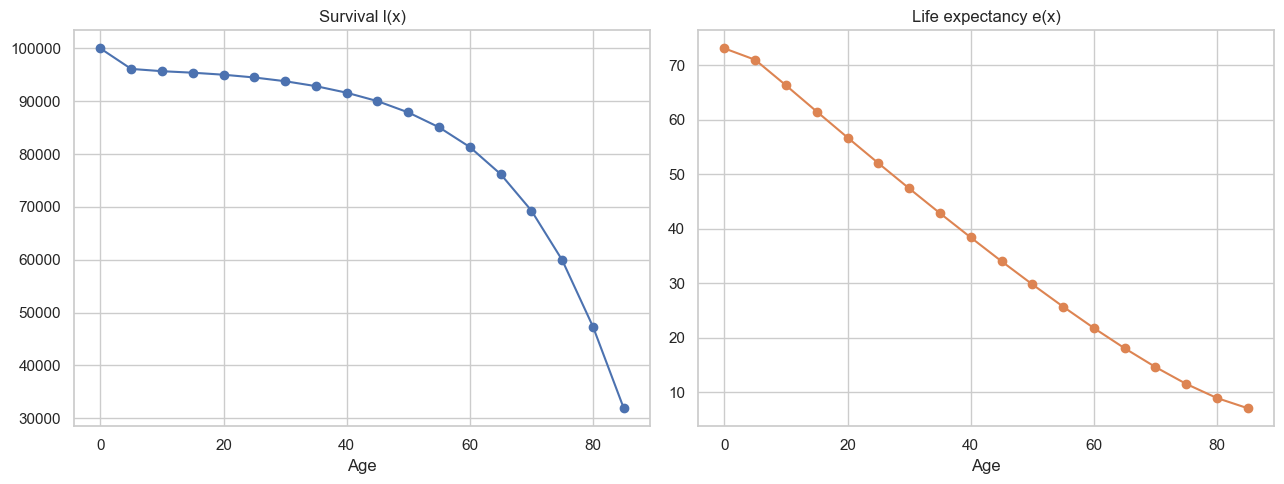

In [15]:
# ============================================================
# 5b. LIFE TABLE VISUALS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(lt.age_start, lt.l_x, marker="o"); axes[0].set_title("Survival l(x)"); axes[0].set_xlabel("Age")
axes[1].plot(lt.age_start, lt.e_x, marker="o", color="C1"); axes[1].set_title("Life expectancy e(x)"); axes[1].set_xlabel("Age")
plt.tight_layout(); plt.show()

## 6. Arithmetic and geometric projections to 2030

Using 2020 and 2025 openings for the **selected district**:

**Arithmetic**: `r_a = (P_2025 − P_2020) / 5` → `P_2030 = P_2025 + 5·r_a`

**Geometric**: `r_g = (P_2025/P_2020)^(1/5) − 1` → `P_2030 = P_2025·(1+r_g)^5`

Neither is "correct" — they encode different assumptions.

In [16]:
# ============================================================
# 6. ARITHMETIC & GEOMETRIC PROJECTIONS (selected district)
# ============================================================
def proj_arith_geom(district_id):
    row = districts.loc[districts.district_id == district_id].iloc[0]
    P2020, P2025 = row.population_2020, row.population_2026  # README: 2026 is 1-Jan-2026 stock; use its own 2025 via age_sex
    # We use 1-Jan-2025 from age_sex and 1-Jan-2026 from districts
    P2025 = age_sex.loc[age_sex.district_id == district_id, "population_2025"].sum()
    P2026 = row.population_2026
    # 2020 anchor uses districts.population_2020
    # r_a uses 5-year window 2020 -> 2025
    r_a = (P2025 - P2020) / 5
    P2030_a = P2025 + 5 * r_a
    r_g = (P2025 / P2020) ** (1/5) - 1
    P2030_g = P2025 * (1 + r_g) ** 5
    return {"district_id": district_id, "P2020": P2020, "P2025": P2025, "P2026": P2026,
            "r_arith": r_a, "r_geom": r_g,
            "P2030_arith": P2030_a, "P2030_geom": P2030_g}

arith_geom = pd.DataFrame([proj_arith_geom(d) for d in [DA, DB]])
print(arith_geom.to_string(index=False))
arith_geom.to_csv(OUT / "growth_projections.csv", index=False)

district_id  P2020  P2025  P2026    r_arith  r_geom  P2030_arith   P2030_geom
        D02 103634 112211 114605 1,715.4000  0.0160 120,788.0000 121,497.8532
        D18 100378 105846 104897 1,093.6000  0.0107 111,314.0000 111,611.8643


## 7. Cohort-component projection (Low / Base / High)

For the selected district only.

**Aging**: `S_{x,s} = P_{x,s,2025} × survival_{x,s}`, then shift up 5 years.
* Survivors from 80-84 join existing 85+ survivors (open group).
* 85+ retention: `P_{85+,2030} = P_{85+,2025} × survival_{85+}`.

**Births** (five-year total):
* `B_2030 = 5·B_2025·fertility_multiplier`
* Sex split: `B_F = 0.49·B_2030`, `B_M = 0.51·B_2030`
* Newborn survival: `B_F·s_F`, `B_M·s_M` → placed in 0-4.

**Migration** (five-year total):
* `I_2030 = 5·I_2025·arrivals_mult`, `O_2030 = 5·O_2025·departures_mult`
* Net applied **end-of-period** to **destination** age band.

**Fertility sensitivity**: rerun Base with High fertility multiplier; hold migration & newborn survival at Base; compare 0-4.

In [17]:
# ============================================================
# 7. COHORT-COMPONENT PROJECTION
# ============================================================
def cohort_component(district_id, scen_row):
    df = age_sex[age_sex.district_id == district_id].copy()

    fm, am, dm = scen_row.fertility_multiplier, scen_row.arrivals_multiplier, scen_row.departures_multiplier
    sf, sm = scen_row.newborn_survival_f, scen_row.newborn_survival_m

    # --- 1. AGING ---
    surv = df.copy()
    surv["pop"] = surv.population_2025 * surv.survival_5yr
    surv["age_next"] = surv.age_start.apply(lambda a: min(a + 5, 85))
    aged = (surv.groupby(["sex","age_next"])["pop"].sum()
            .reset_index().rename(columns={"age_next":"age_start"}))

    # --- 2. MIGRATION (five-year, scaled) ---
    mig = df.copy()
    mig["net"] = 5 * (mig.arrivals_2025 * am - mig.departures_2025 * dm)
    mig = mig.groupby(["sex","age_start"])["net"].sum().reset_index()

    out = aged.merge(mig, on=["sex","age_start"], how="left").fillna({"net":0})
    out["pop"] += out["net"]

    # --- 3. BIRTHS ---
    B5 = 5 * df.loc[df.sex == "F", "births_to_women_2025"].sum() * fm
    newborns = pd.DataFrame({
        "sex":      ["F","M"],
        "age_start":[0,0],
        "pop":      [B5 * 0.49 * sf, B5 * 0.51 * sm],
    })
    out = pd.concat([out, newborns], ignore_index=True)
    out = out.groupby(["sex","age_start"])["pop"].sum().reset_index()
    out["district_id"] = district_id
    return out

# Run all three scenarios for both selected districts
records = []
for _, s in scen.iterrows():
    for d in [DA, DB]:
        p = cohort_component(d, s)
        p["scenario"] = s.scenario
        records.append(p)
proj = pd.concat(records, ignore_index=True)
print(proj.groupby(["district_id","scenario"])["pop"].sum().round(0).to_string())
proj.to_csv(OUT / "cohort_projection.csv", index=False)

# --- 4. FERTILITY SENSITIVITY ---
base_row = scen.loc[scen.scenario=="Base"].iloc[0].copy()
high_row = scen.loc[scen.scenario=="High"].iloc[0]
sens_row = base_row.copy(); sens_row.fertility_multiplier = high_row.fertility_multiplier

sens_records = []
for d in [DA, DB]:
    p_base = cohort_component(d, base_row)
    p_mod  = cohort_component(d, sens_row)
    b04 = p_base.loc[p_base.age_start==0, "pop"].sum()
    m04 = p_mod.loc[p_mod.age_start==0, "pop"].sum()
    sens_records.append({"district_id": d, "pop_0_4_base": b04,
                         "pop_0_4_mod": m04, "delta_0_4": m04 - b04})
sens_df = pd.DataFrame(sens_records)
print("\n=== FERTILITY SENSITIVITY (0-4 population) ===")
print(sens_df.to_string(index=False))
sens_df.to_csv(OUT / "fertility_sensitivity.csv", index=False)

district_id  scenario
D02          Base       124,430.0000
             High       129,310.0000
             Low        119,594.0000
D18          Base       102,571.0000
             High       106,092.0000
             Low         99,072.0000

=== FERTILITY SENSITIVITY (0-4 population) ===
district_id  pop_0_4_base  pop_0_4_mod  delta_0_4
        D02   12,076.6080  13,525.8010 1,449.1930
        D18    6,398.6544   7,166.4929   767.8385


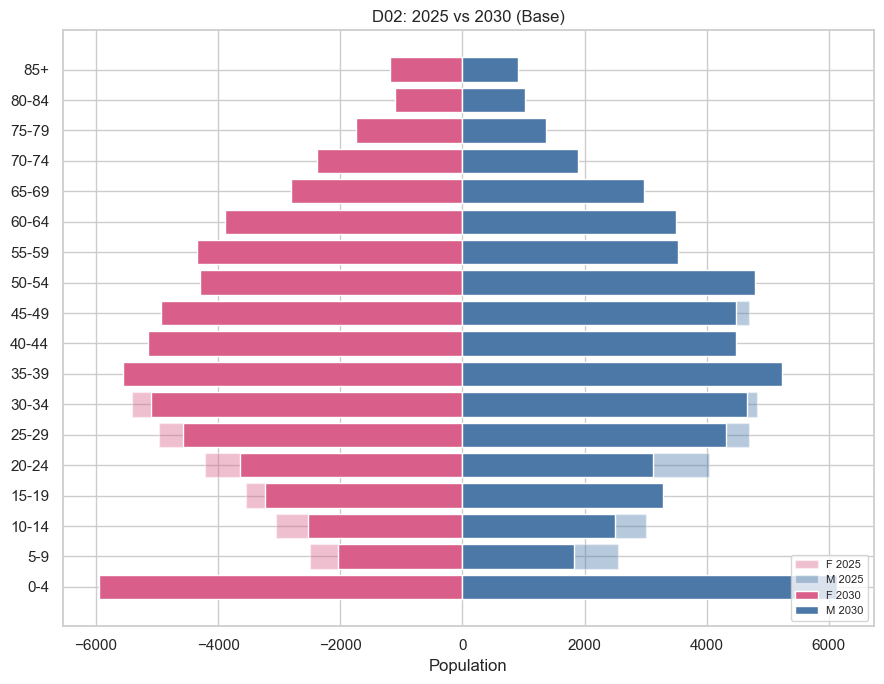

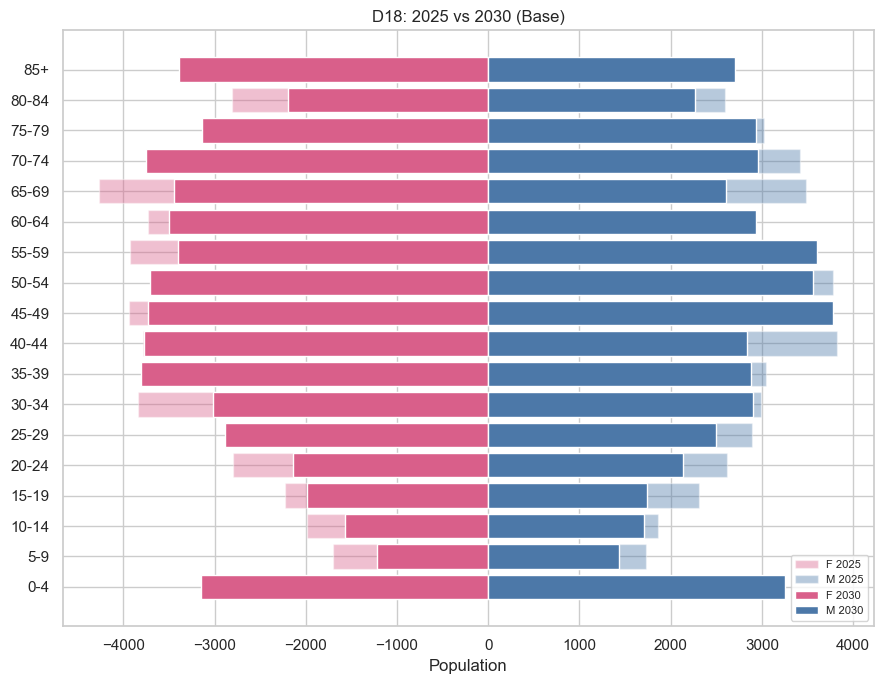

In [18]:
# ============================================================
# 7b. PROJECTION VISUAL — pyramid comparison Base 2025 vs 2030
# ============================================================
for d in [DA, DB]:
    p25 = age_sex[age_sex.district_id==d].groupby(["age_start","sex"])["population_2025"].sum().unstack("sex").reindex(AGE_BANDS, fill_value=0)
    p30 = proj[(proj.district_id==d)&(proj.scenario=="Base")].groupby(["age_start","sex"])["pop"].sum().unstack("sex").reindex(AGE_BANDS, fill_value=0)
    fig, ax = plt.subplots(figsize=(9,7))
    y = [age_label(a) for a in AGE_BANDS]
    ax.barh(y, -p25["F"], color="#d95f8a", alpha=0.4, label="F 2025")
    ax.barh(y,  p25["M"], color="#4c78a8", alpha=0.4, label="M 2025")
    ax.barh(y, -p30["F"], color="#d95f8a", label="F 2030")
    ax.barh(y,  p30["M"], color="#4c78a8", label="M 2030")
    ax.set_title(f"{d}: 2025 vs 2030 (Base)")
    ax.set_xlabel("Population"); ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()

## 8. Three-state continuous-time Markov model (insurer)

**States**: H (healthy), I (ill), D (dead, absorbing).

**Intensities** (pooled across all 24 districts):
`λ_ij = N_ij / E_i` — with **exposure counted once per district-origin**.

**Generator** (H, I, D order):

In [ ]:

**Holding time in state i**: `1 / -Q_ii`.

**Next-jump probabilities**: `λ_ij / Σ_j λ_ij` — *distinct* from occupancy.

**Transition matrices**: `P(1)=expm(Q)`, `P(2)=expm(2Q)`; check `P(2) ≈ P(1)^2`.

**Occupancy**: `n_1 = n_0 P(1)`, `n_2 = n_0 P(2)`.

**Claims** (USD 1,000 per death):
`C_1 = 1000·(D_1 − D_0)`, `C_2 = 1000·(D_2 − D_1)`.

In [20]:
# ============================================================
# 8. MARKOV MODEL
# ============================================================
# De-duplicate exposure and initial lives per district-origin
origin_level = (trans.groupby(["district_id","origin"])
                .agg(exposure_py=("exposure_py","first"),
                     initial_lives=("initial_lives","first"))
                .reset_index())

# Pool transition counts across districts
pooled = (trans.groupby(["origin","destination"])
          .agg(N=("transition_count","sum")).reset_index())
pooled_exp = (origin_level.groupby("origin")
              .agg(E=("exposure_py","sum")).reset_index())
pooled = pooled.merge(pooled_exp, on="origin")
pooled["lambda_"] = pooled.N / pooled.E      # <-- renamed (was "lambda")

print("=== POOLED INTENSITIES ===")
print(pooled.to_string(index=False))

# Generator matrix (H, I, D)
S = ["H","I","D"]
Q = np.zeros((3,3))
for _, r in pooled.iterrows():
    i, j = S.index(r.origin), S.index(r.destination)
    Q[i,j] = r.lambda_
for i in range(3):
    Q[i,i] = -Q[i].sum()
print("\n=== GENERATOR Q ===")
print(pd.DataFrame(Q, index=S, columns=S).round(6).to_string())

assert np.allclose(Q.sum(axis=1), 0), "Rows must sum to zero"
assert (Q[2] == 0).all() and Q[2,2] == 0
print("✔ Q checks passed")

=== POOLED INTENSITIES ===
origin destination    N     E  lambda_
     H           D  895 49764   0.0180
     H           I 5152 49764   0.1035
     I           D  970 14417   0.0673
     I           H 3533 14417   0.2451

=== GENERATOR Q ===
        H       I       D
H -0.1215  0.1035  0.0180
I  0.2451 -0.3123  0.0673
D  0.0000  0.0000 -0.0000
✔ Q checks passed


In [21]:
# ============================================================
# 8b. HOLDING TIMES, P(1), P(2), OCCUPANCY, CLAIMS
# ============================================================
holding = {s: 1/(-Q[S.index(s), S.index(s)]) for s in ["H","I"]}
print("Mean holding times (years):")
for k,v in holding.items(): print(f"  {k}: {v:.3f}")

# Next-jump probabilities from I
lIH, lID = pooled.loc[(pooled.origin=="I")&(pooled.destination=="H"),"lambda_"].iloc[0], \
           pooled.loc[(pooled.origin=="I")&(pooled.destination=="D"),"lambda_"].iloc[0]
print(f"\nNext-jump from I: H={lIH/(lIH+lID):.4f}, D={lID/(lIH+lID):.4f}")

# P(1) and P(2)
P1 = expm(Q * 1)
P2 = expm(Q * 2)
print("\n=== P(1) ==="); print(pd.DataFrame(P1, index=S, columns=S).round(6).to_string())
print("\n=== P(2) ==="); print(pd.DataFrame(P2, index=S, columns=S).round(6).to_string())
print("\nCheck P(2) ≈ P(1)^2:", np.allclose(P2, P1 @ P1, atol=1e-9))
print("Row sums P(1):", P1.sum(axis=1).round(6))
print("Row sums P(2):", P2.sum(axis=1).round(6))

# Occupancy
n0_H = origin_level.loc[origin_level.origin=="H", "initial_lives"].sum()
n0_I = origin_level.loc[origin_level.origin=="I", "initial_lives"].sum()
n0 = np.array([n0_H, n0_I, 0.0])
n1 = n0 @ P1
n2 = n0 @ P2
print(f"\n=== OCCUPANCY ===")
print(f"n0: H={n0[0]:,.0f}  I={n0[1]:,.0f}  D={n0[2]:,.0f}")
print(f"n1: H={n1[0]:,.0f}  I={n1[1]:,.0f}  D={n1[2]:,.0f}")
print(f"n2: H={n2[0]:,.0f}  I={n2[1]:,.0f}  D={n2[2]:,.0f}")

# Claims (USD 1,000 per covered death)
C1 = 1000 * (n1[2] - n0[2])
C2 = 1000 * (n2[2] - n1[2])
print(f"\n=== EXPECTED CLAIMS ===")
print(f"Year 1: ${C1:,.0f}")
print(f"Year 2: ${C2:,.0f}")

# Export
pd.DataFrame({"state":S,"n0":n0,"n1":n1,"n2":n2}).to_csv(OUT/"markov_occupancy.csv", index=False)
pd.DataFrame({"year":[1,2],"claims_usd":[C1,C2]}).to_csv(OUT/"expected_claims.csv", index=False)
pooled.rename(columns={"lambda_":"intensity"}).to_csv(OUT/"markov_intensities.csv", index=False)
pd.DataFrame(P1,index=S,columns=S).to_csv(OUT/"markov_P1.csv")
pd.DataFrame(P2,index=S,columns=S).to_csv(OUT/"markov_P2.csv")

Mean holding times (years):
  H: 8.230
  I: 3.202

Next-jump from I: H=0.7846, D=0.2154

=== P(1) ===
       H      I      D
H 0.8962 0.0838 0.0200
I 0.1984 0.7417 0.0599
D 0.0000 0.0000 1.0000

=== P(2) ===
       H      I      D
H 0.8197 0.1373 0.0430
I 0.3249 0.5667 0.1084
D 0.0000 0.0000 1.0000

Check P(2) ≈ P(1)^2: True
Row sums P(1): [1. 1. 1.]
Row sums P(2): [1. 1. 1.]

=== OCCUPANCY ===
n0: H=20,080  I=3,576  D=0
n1: H=18,704  I=4,335  D=617
n2: H=17,622  I=4,783  D=1,251

=== EXPECTED CLAIMS ===
Year 1: $616,501
Year 2: $634,457


## 9. District clustering

**Features** (one row per district, all 24 kept):

| Feature | Calculation |
|---|---|
| under15_share | `P_0-14 / P_total` |
| over65_share  | `P_65+ / P_total` |
| net_migration_rate | `(I − O) / E × 1000` |
| piped_water_pct | supplied; region-mean imputation for D04, D17; flagged |

**Standardise** z-scores (do *not* include district_id as a feature).

**Choose k**: WCSS elbow + silhouette for k=2..6.

**Stability**: refit with different seed and with alternate imputation; compare with **Adjusted Rand Index**.

In [22]:
# ============================================================
# 9. CLUSTERING DATASET
# ============================================================
cluster_df = ind.copy()
cluster_df = cluster_df.merge(balance[["district_id","NMR"]], on="district_id", how="left")
cluster_df = cluster_df.rename(columns={
    "pct_under15":"under15_share",
    "pct_65plus":"over65_share",
    "NMR":"net_migration_rate",
})
# Impute missing water with regional mean (flag)
cluster_df["water_missing"] = cluster_df.piped_water_pct.isna()
region_mean = cluster_df.groupby("region").piped_water_pct.transform("mean")
cluster_df["piped_water_imputed"] = cluster_df.piped_water_pct.fillna(region_mean)

FEATS = ["under15_share","over65_share","net_migration_rate","piped_water_imputed"]
X = cluster_df[FEATS].copy()
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

print("Clustering features (head):")
print(cluster_df[["district_id"] + FEATS + ["water_missing"]].head(10).to_string(index=False))

Clustering features (head):
district_id  under15_share  over65_share  net_migration_rate  piped_water_imputed  water_missing
        D01        29.2748       14.6337             -2.6921              31.3000          False
        D02        13.2928       12.4088              9.5849              80.5000          False
        D03         9.2829       27.9718             -2.3225              56.6000          False
        D04        27.8828       14.3873             -3.6670              53.6500           True
        D05        12.9661       12.4177             13.9906              77.4000          False
        D06         9.5187       28.1999             -1.2655              50.4000          False
        D07        29.4594       14.5867             -2.2857              44.5000          False
        D08        12.8658       12.4281             12.5759              72.9000          False
        D09         9.0270       27.8399             -1.4208              53.6000          False
  

WCSS: {1: 96.00000000000001, 2: 45.01895231488234, 3: 5.483210930974456, 4: 3.4499547347391633, 5: 2.1703773723143955, 6: 1.3068163878492798}
Silhouette: {2: 0.558262845447401, 3: 0.8168622856886056, 4: 0.7410319825152025, 5: 0.6315667867970456, 6: 0.6201044834778332}


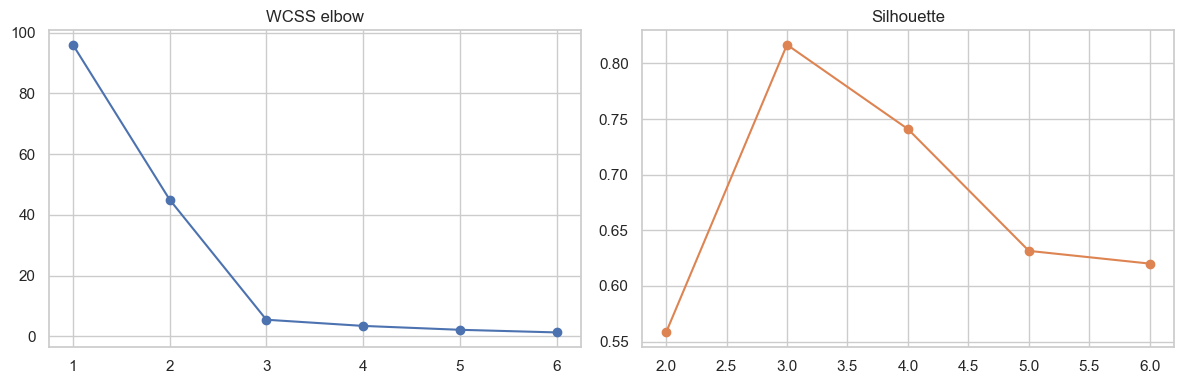

Chosen k (best silhouette): 3
ARI (seed 42 vs seed 7): 1.000

Cluster centroids (original units):
         under15_share  over65_share  net_migration_rate  piped_water_imputed
cluster                                                                      
0               9.4900       27.8900             -1.5400              53.7900
1              12.9000       12.5600             11.8600              75.9300
2              28.9700       14.5900             -2.7600              38.7100

Cluster sizes:
cluster
0    8
1    8
2    8


In [23]:
# ============================================================
# 9b. CHOOSE K, FIT FINAL, STABILITY
# ============================================================
wcss, sil = {}, {}
for k in range(1, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    wcss[k] = km.inertia_
    if k >= 2:
        sil[k] = silhouette_score(Xs, km.labels_)
print("WCSS:", wcss); print("Silhouette:", sil)

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(list(wcss), list(wcss.values()), marker="o"); axes[0].set_title("WCSS elbow")
axes[1].plot(list(sil), list(sil.values()), marker="o", color="C1"); axes[1].set_title("Silhouette")
plt.tight_layout(); plt.show()

# Choose k with best silhouette (interpretability may adjust)
k_best = max(sil, key=sil.get)
print(f"Chosen k (best silhouette): {k_best}")

km_final = KMeans(n_clusters=k_best, n_init=20, random_state=42).fit(Xs)
cluster_df["cluster"] = km_final.labels_

# Stability: reseed
km_alt = KMeans(n_clusters=k_best, n_init=20, random_state=7).fit(Xs)
ari = adjusted_rand_score(km_final.labels_, km_alt.labels_)
print(f"ARI (seed 42 vs seed 7): {ari:.3f}")

# Centroids in ORIGINAL units
centroids = pd.DataFrame(scaler.inverse_transform(km_final.cluster_centers_),
                         columns=FEATS).round(2)
centroids.index.name = "cluster"
print("\nCluster centroids (original units):")
print(centroids.to_string())

print("\nCluster sizes:"); print(cluster_df.cluster.value_counts().sort_index().to_string())

cluster_df.to_csv(OUT/"clustering_results.csv", index=False)
pd.DataFrame({"k":list(wcss),"WCSS":list(wcss.values())}).to_csv(OUT/"cluster_diagnostics_wcss.csv", index=False)
pd.DataFrame({"k":list(sil),"silhouette":list(sil.values())}).to_csv(OUT/"cluster_diagnostics_silhouette.csv", index=False)

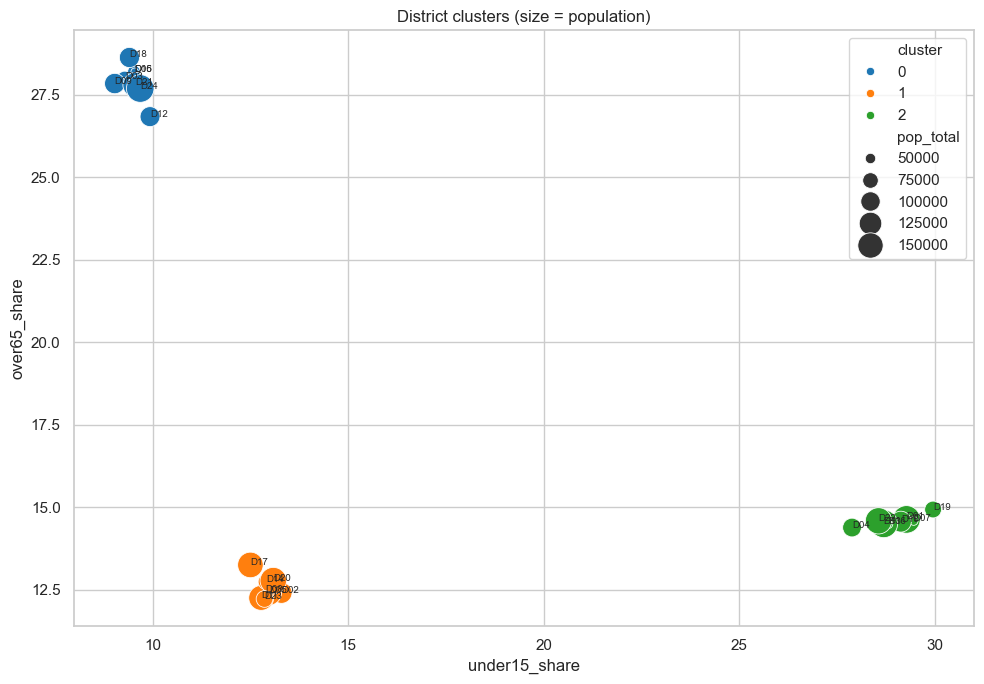

In [24]:
# ============================================================
# 9c. CLUSTER VISUAL
# ============================================================
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(data=cluster_df, x="under15_share", y="over65_share",
                hue="cluster", size="pop_total", sizes=(30,400), palette="tab10", ax=ax)
for _, r in cluster_df.iterrows():
    ax.annotate(r.district_id, (r.under15_share, r.over65_share), fontsize=7)
ax.set_title("District clusters (size = population)")
plt.tight_layout(); plt.show()

## 10. Exports and reproducibility

All Power BI data exports live in `output/`. Interpretation notes below feed directly into the six-page report.

In [25]:
# ============================================================
# 10. EXPORT MANIFEST
# ============================================================
# district_profiles.csv
ind.merge(balance[["district_id","CBR","CDR","NMR","balance_gap"]], on="district_id") \
   .to_csv(OUT/"district_profiles.csv", index=False)

# population_pyramid.csv (only the two selected districts)
pyr = (age_sex[age_sex.district_id.isin([DA,DB])]
       .groupby(["district_id","age_start","sex"])["population_2025"].sum()
       .reset_index())
pyr.to_csv(OUT/"population_pyramid.csv", index=False)

print("=== OUTPUT MANIFEST ===")
for f in sorted(OUT.glob("*.csv")):
    print(f"  {f.name:35s} {len(pd.read_csv(f)):>5d} rows")

print("\n=== HEADLINE RESULTS ===")
print(f"Selected District A: {DA}")
print(f"Selected District B: {DB}")
print(f"Life expectancy at birth: {e0:.2f}")
print(f"Life expectancy at 65:    {e65:.2f}")
print(f"Chosen k for clustering:  {k_best} (silhouette={sil[k_best]:.3f})")
print(f"Year-1 expected claims:   ${C1:,.0f}")
print(f"Year-2 expected claims:   ${C2:,.0f}")

=== OUTPUT MANIFEST ===
  cluster_diagnostics_silhouette.csv      5 rows
  cluster_diagnostics_wcss.csv            6 rows
  clustering_results.csv                 24 rows
  cohort_projection.csv                 216 rows
  data_quality_log.csv                    5 rows
  demographic_rates.csv                  24 rows
  district_profiles.csv                  24 rows
  expected_claims.csv                     2 rows
  fertility_sensitivity.csv               2 rows
  growth_projections.csv                  2 rows
  life_table.csv                         18 rows
  markov_intensities.csv                  4 rows
  markov_occupancy.csv                    3 rows
  markov_P1.csv                           3 rows
  markov_P2.csv                           3 rows
  population_pyramid.csv                 72 rows

=== HEADLINE RESULTS ===
Selected District A: D02
Selected District B: D18
Life expectancy at birth: 73.11
Life expectancy at 65:    18.10
Chosen k for clustering:  3 (silhouette=0.817)
Year-

## Interpretation (feeds report)

### Planning team
* **Structure** — District A and B contrast sharply in youth/old shares; dependency ratios differ accordingly. Policy implications: schools/maternal services vs pensions/eldercare.
* **Growth drivers** — Compare CBR, CDR and NMR to classify districts as birth-driven vs migration-driven.
* **2030 projections** — Arithmetic vs geometric diverge most where growth is nonlinear. Cohort-component is the recommended operational view, with Low/Base/High communicating uncertainty honestly.
* **Fertility sensitivity** — The 0-4 population is highly elastic to fertility assumptions; highlights planning sensitivity to future birth rates.
* **Clustering** — Districts fall into coherent groups; report centroid profiles in original units.

### Insurer
* **Intensity vs probability** — Pooled intensities are not the same as probabilities of occupancy. Report both.
* **Holding times** — Mean time in H and I informs reserving and claims frequency expectations.
* **P(1), P(2)** — Consistent (P(2) ≈ P(1)²); rows sum to 1; D absorbing.
* **Occupancy & claims** — Year-1 and Year-2 expected claims separated; provide both to the client.

### Caveats
* Synthetic data — not real Zimbabwe demographics.
* Two missing `piped_water_pct` values (D04, D17) imputed by region mean; flagged and stability-tested via ARI.
* Projections are **conditional**, not forecasts — state assumptions explicitly.
* Mortality schedules in `life_table_inputs` are pooled across sexes, illustrative only.
* Markov model assumes **time-homogeneous** intensities.

### Reproducibility
* Environment: Python 3.10+, pandas, numpy, matplotlib, seaborn, scipy, scikit-learn.
* Run top-to-bottom; outputs written to `output/`.
* Random seeds fixed (42 for main fit, 7 for stability check).

In [26]:
import os
print(sorted(os.listdir("output")))

['cluster_diagnostics_silhouette.csv', 'cluster_diagnostics_wcss.csv', 'clustering_results.csv', 'cohort_projection.csv', 'data_quality_log.csv', 'demographic_rates.csv', 'district_profiles.csv', 'expected_claims.csv', 'fertility_sensitivity.csv', 'growth_projections.csv', 'life_table.csv', 'markov_P1.csv', 'markov_P2.csv', 'markov_intensities.csv', 'markov_occupancy.csv', 'population_pyramid.csv']


In [27]:
# Life expectancy
print(pd.read_csv("output/life_table.csv")[["age_label","e_x"]].head(3))

# Expected claims
print(pd.read_csv("output/expected_claims.csv"))

# Cluster membership
print(pd.read_csv("output/clustering_results.csv")[["district_id","cluster"]].head())

  age_label     e_x
0       0-4 73.1091
1       5-9 71.0134
2     10-14 66.3224
   year   claims_usd
0     1 616,500.6313
1     2 634,456.5391
  district_id  cluster
0         D01        2
1         D02        1
2         D03        0
3         D04        2
4         D05        1


In [1]:
# ============================================================
# 11. BUILD POWER BI EXCEL DATABASE
# ============================================================
from pathlib import Path
import pandas as pd
import numpy as np

OUT = Path("output")

# 1. Create the Dimensions in Python
# ------------------------------------------------------------
# dim_district
df_district = pd.read_csv(OUT / "district_profiles.csv")
dim_district = df_district[['district_id', 'district_name', 'region', 'piped_water_pct']].drop_duplicates()

# dim_age
age_starts = list(range(0, 90, 5))
def get_age_label(a): return f"{a}-{a+4}" if a < 85 else "85+"
def get_broad_group(a): return "0-14" if a < 15 else ("15-64" if a < 65 else "65+")

dim_age = pd.DataFrame({
    'age_start': age_starts,
    'age_label': [get_age_label(a) for a in age_starts],
    'broad_group': [get_broad_group(a) for a in age_starts]
})

# dim_scenario
dim_scenario = pd.DataFrame({
    'scenario': ['Low', 'Base', 'High'],
    'scenario_order': [1, 2, 3] # Useful for sorting in Power BI
})

# dim_state
dim_state = pd.DataFrame({
    'state': ['H', 'I', 'D'],
    'state_name': ['Healthy', 'Ill', 'Dead']
})

# 2. Load all the Fact tables
# ------------------------------------------------------------
fact_files = [
    "population_pyramid", "cohort_projection", "demographic_rates", 
    "life_table", "growth_projections", "fertility_sensitivity", 
    "markov_intensities", "markov_P1", "markov_P2", 
    "markov_occupancy", "expected_claims", "clustering_results",
    "cluster_diagnostics_wcss", "cluster_diagnostics_silhouette"
]

tables = {
    "dim_district": dim_district,
    "dim_age": dim_age,
    "dim_scenario": dim_scenario,
    "dim_state": dim_state
}

for f in fact_files:
    try:
        tables[f] = pd.read_csv(OUT / f"{f}.csv")
    except FileNotFoundError:
        print(f"Warning: {f}.csv not found in {OUT}")

# 3. Export to a single Excel File
# ------------------------------------------------------------
excel_filename = OUT / "PowerBI_Database.xlsx"
print(f"\nWriting tables to {excel_filename}...")

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    for sheet_name, df in tables.items():
        # Excel sheet names max out at 31 chars
        safe_sheet_name = sheet_name[:31] 
        df.to_excel(writer, sheet_name=safe_sheet_name, index=False)
        print(f"  -> Saved sheet: {safe_sheet_name} ({len(df)} rows)")

print("\nExcel file created successfully! You can now load this into Power BI.")


Writing tables to output\PowerBI_Database.xlsx...
  -> Saved sheet: dim_district (24 rows)
  -> Saved sheet: dim_age (18 rows)
  -> Saved sheet: dim_scenario (3 rows)
  -> Saved sheet: dim_state (3 rows)
  -> Saved sheet: population_pyramid (72 rows)
  -> Saved sheet: cohort_projection (216 rows)
  -> Saved sheet: demographic_rates (24 rows)
  -> Saved sheet: life_table (18 rows)
  -> Saved sheet: growth_projections (2 rows)
  -> Saved sheet: fertility_sensitivity (2 rows)
  -> Saved sheet: markov_intensities (4 rows)
  -> Saved sheet: markov_P1 (3 rows)
  -> Saved sheet: markov_P2 (3 rows)
  -> Saved sheet: markov_occupancy (3 rows)
  -> Saved sheet: expected_claims (2 rows)
  -> Saved sheet: clustering_results (24 rows)
  -> Saved sheet: cluster_diagnostics_wcss (6 rows)
  -> Saved sheet: cluster_diagnostics_silhouette (5 rows)

Excel file created successfully! You can now load this into Power BI.
